# Plots

In [1]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('..')

from main import *
from utils import *

## 1. Spectrogram plot 
A. Database Recording

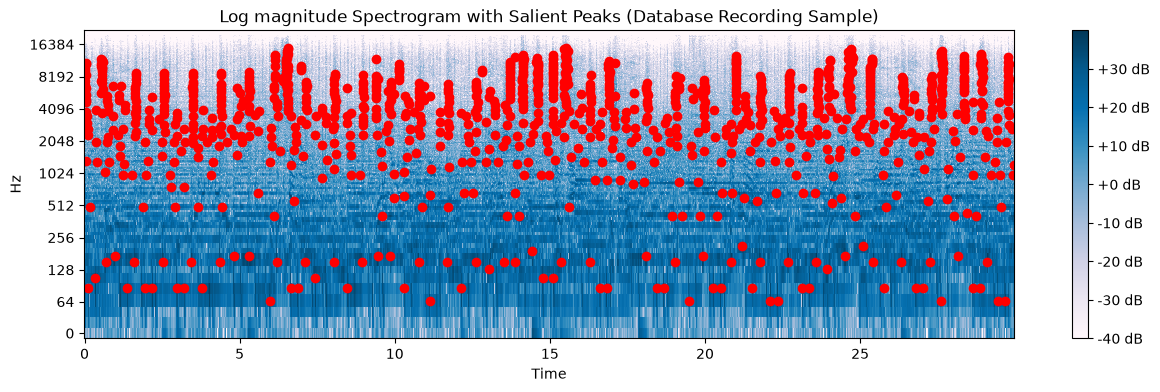

In [6]:
sr = SR
n_fft = N_FFT
window_length = WINDOW_LENGTH
hop_length = HOP_LENGTH

database_dir = '../audio_data/database/'
sample_file = os.path.join(database_dir, '051271.mp3')
spectrogram = to_spectrogram(sample_file, sr, hop_length, window_length, n_fft)

peaks = constellation(spectrogram, level_threshold=LEVEL_THRESHOLD_DB, neighbourhood_size=NEIGHBOURHOOD_SIZE)
freq_bins, time_frames = peaks[:, 0], peaks[:, 1]

bin_idx, frame_idx = zip(*peaks)

times = librosa.frames_to_time(frame_idx, sr=sr, hop_length=hop_length)
freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)[list(bin_idx)]

fig, ax = plt.subplots(1, 1, figsize=(15,4))
img = librosa.display.specshow(spectrogram, y_axis='log',x_axis='time',
                               sr=sr, hop_length=hop_length, ax=ax, cmap='PuBu')

ax.scatter(x=times, y= freqs, c='red')
fig.colorbar(img, ax=ax, format='%+2.0f dB')                           
ax.set(title='Log magnitude Spectrogram with Salient Peaks (Database Recording Sample)')
plt.show()



B. Query Recording

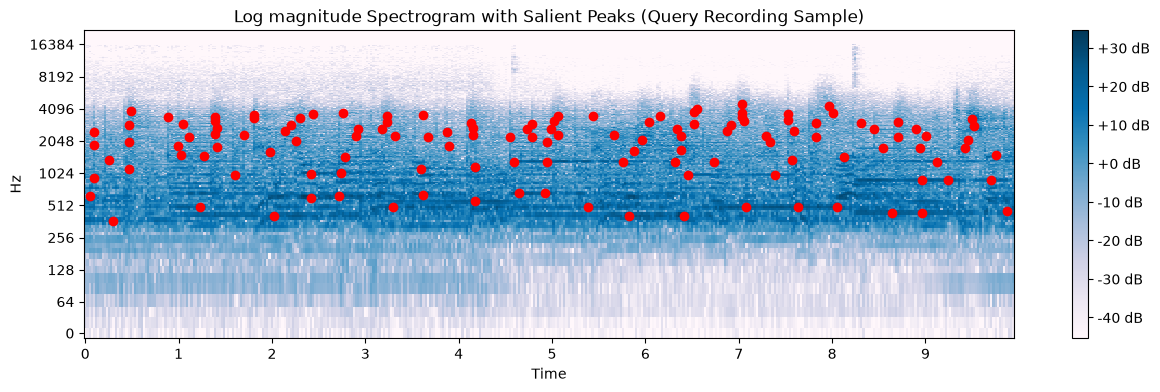

In [8]:
sr = SR
n_fft = N_FFT
window_length = WINDOW_LENGTH
hop_length = HOP_LENGTH

database_dir = '../audio_data/query/'
sample_file = os.path.join(database_dir, '051271_query.mp3')
spectrogram = to_spectrogram(sample_file, sr, hop_length, window_length, n_fft)

peaks = constellation(spectrogram, level_threshold=LEVEL_THRESHOLD_DB, neighbourhood_size=NEIGHBOURHOOD_SIZE)
freq_bins, time_frames = peaks[:, 0], peaks[:, 1]

bin_idx, frame_idx = zip(*peaks)

times = librosa.frames_to_time(frame_idx, sr=sr, hop_length=hop_length)
freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)[list(bin_idx)]

fig, ax = plt.subplots(1, 1, figsize=(15,4))
img = librosa.display.specshow(spectrogram, y_axis='log',x_axis='time',
                               sr=sr, hop_length=hop_length, ax=ax, cmap='PuBu')

ax.scatter(x=times, y= freqs, c='red')
fig.colorbar(img, ax=ax, format='%+2.0f dB')                           
ax.set(title='Log magnitude Spectrogram with Salient Peaks (Query Recording Sample)')
plt.show()
